# ✍️ Handwritten Character Recognition — CodeAlpha ML Internship (Task 3)

**Objective:** identify handwritten characters and alphabets with image processing and deep learning.

**Data:** [EMNIST](https://www.kaggle.com/datasets/crawford/emnist) (characters) · MNIST (digits)

**Models:** CNN for single characters · CRNN (CNN + BiLSTM + CTC) for full words

▶️ Settings → Accelerator → **GPU**, add the EMNIST input, then **Run All**.

## 1. Setup — imports & settings
`DATASET`: `"balanced"` (47 classes: digits + letters), `"letters"` (26), `"digits"` or `"mnist"`.

In [1]:
import glob, json, os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow import keras
from tensorflow.keras import layers

DATASET = "balanced"      # "balanced" (47 classes) | "letters" (26) | "digits" | "mnist"
EPOCHS = 30
CRNN_STEPS = 6000
SEED = 42
INPUT = "/kaggle/input" if os.path.exists("/kaggle/input") else "."
OUT = "/kaggle/working/outputs" if os.path.exists("/kaggle/working") else "outputs"
os.makedirs(OUT, exist_ok=True)
tf.random.set_seed(SEED); np.random.seed(SEED)
print("GPU:", tf.config.list_physical_devices("GPU"))

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 2. Data helpers
The Kaggle EMNIST CSVs store each image **transposed**, so the loader fixes the orientation.

In [2]:
CHARSETS = {"mnist": "0123456789", "digits": "0123456789",
            "letters": "ABCDEFGHIJKLMNOPQRSTUVWXYZ",
            "balanced": "0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZabdefghnqrt"}


def load_emnist(split):
    """Kaggle EMNIST CSV: label + 784 pixels, images stored transposed -> fix orientation."""
    def read(part):
        f = glob.glob(f"{INPUT}/**/emnist-{split}-{part}.csv", recursive=True)
        assert f, f"emnist-{split}-{part}.csv not found - attach the crawford/emnist dataset"
        d = pd.read_csv(f[0], header=None).values
        return d[:, 1:].reshape(-1, 28, 28).transpose(0, 2, 1).astype(np.uint8), d[:, 0]
    (x_tr, y_tr), (x_te, y_te) = read("train"), read("test")
    cls = np.unique(y_tr)                                    # e.g. letters 1..26 -> 0..25
    return (x_tr, np.searchsorted(cls, y_tr)), (x_te, np.searchsorted(cls, y_te))


def show_grid(imgs, titles, path, n=25):
    plt.figure(figsize=(7, 7))
    for i in range(min(n, len(imgs))):
        plt.subplot(5, 5, i + 1); plt.imshow(imgs[i].squeeze(), cmap="gray")
        plt.title(titles[i], fontsize=9); plt.axis("off")
    plt.tight_layout(); plt.savefig(path, dpi=120); plt.show()

# Part A — CNN character recognition
## 3. Load data & check samples
The grid below must show upright characters with the correct labels.

balanced: train (112800, 28, 28), test (18800, 28, 28), 47 classes


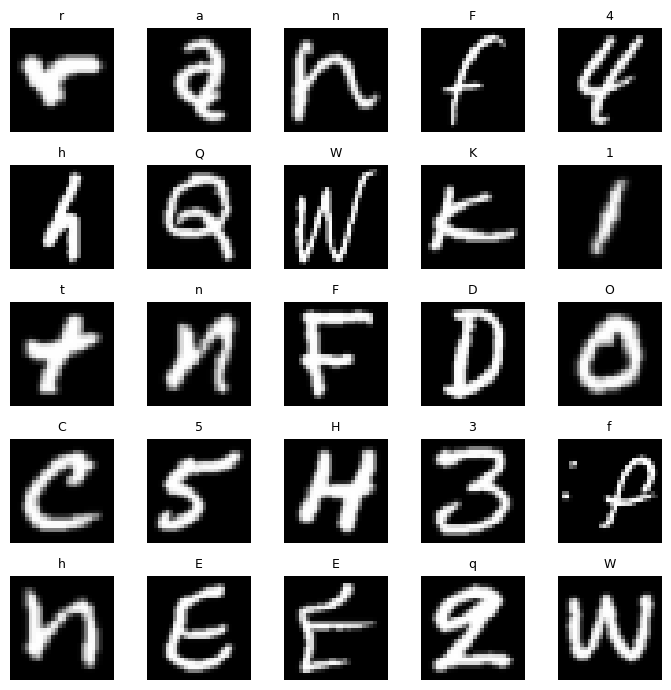

In [3]:
if DATASET == "mnist":
    (x_tr, y_tr), (x_te, y_te) = keras.datasets.mnist.load_data()
else:
    (x_tr, y_tr), (x_te, y_te) = load_emnist(DATASET)
charset = CHARSETS[DATASET]
N = len(charset)
print(f"{DATASET}: train {x_tr.shape}, test {x_te.shape}, {N} classes")
show_grid(x_tr[:25], [charset[i] for i in y_tr[:25]], f"{OUT}/samples.png")   # check: upright + correct labels

## 4. Normalise pixels to [0, 1]

In [4]:
x_tr = (x_tr.astype("float32") / 255.0)[..., None]
x_te = (x_te.astype("float32") / 255.0)[..., None]

## 5. Build the CNN
- light **augmentation** (rotation, shift, zoom — no flips, they change characters)
- 3 conv blocks (2 × Conv3×3 → BatchNorm → ReLU, MaxPool, Dropout): edges → strokes → character parts
- Dense(256) + Dropout → softmax

In [5]:
def conv_block(x, f, drop):
    for _ in range(2):
        x = layers.Conv2D(f, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
    return layers.Dropout(drop)(layers.MaxPooling2D()(x))


inp = keras.Input((28, 28, 1))
x = keras.Sequential([layers.RandomRotation(0.04), layers.RandomTranslation(0.08, 0.08),
                      layers.RandomZoom(0.08)], name="augmentation")(inp)      # no flips: they change characters
x = conv_block(x, 32, 0.20)
x = conv_block(x, 64, 0.25)
x = conv_block(x, 128, 0.30)
x = layers.Flatten()(x)
x = layers.Dense(256, use_bias=False)(x)
x = layers.Dropout(0.4)(layers.ReLU()(layers.BatchNormalization()(x)))
cnn = keras.Model(inp, layers.Dense(N, activation="softmax")(x), name="char_cnn")
cnn.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
cnn.summary()

Model: "char_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 7, 7, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 7, 7, 128)      │       147,456 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 595,791 (2.27 MB)

 Trainable params: 594,383 (2.27 MB)

 Non-trainable params: 1,408 (5.50 KB)

## 6. Train (early stopping + learning-rate reduction)

In [6]:
hist = cnn.fit(x_tr, y_tr, validation_split=0.1, epochs=EPOCHS, batch_size=128, verbose=2, callbacks=[
    keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=6, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5)])

Epoch 1/30


E0000 00:00:1795575938.340351      50 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/char_cnn_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


794/794 - 28s - 35ms/step - accuracy: 0.6876 - loss: 1.0454 - val_accuracy: 0.8544 - val_loss: 0.4065 - learning_rate: 0.0010
Epoch 2/30
794/794 - 18s - 23ms/step - accuracy: 0.8264 - loss: 0.5025 - val_accuracy: 0.8591 - val_loss: 0.3944 - learning_rate: 0.0010
Epoch 3/30
794/794 - 19s - 23ms/step - accuracy: 0.8441 - loss: 0.4437 - val_accuracy: 0.8666 - val_loss: 0.3704 - learning_rate: 0.0010
Epoch 4/30
794/794 - 19s - 24ms/step - accuracy: 0.8536 - loss: 0.4100 - val_accuracy: 0.8806 - val_loss: 0.3172 - learning_rate: 0.0010
Epoch 5/30
794/794 - 19s - 24ms/step - accuracy: 0.8592 - loss: 0.3889 - val_accuracy: 0.8512 - val_loss: 0.4039 - learning_rate: 0.0010
Epoch 6/30
794/794 - 19s - 24ms/step - accuracy: 0.8643 - loss: 0.3758 - val_accuracy: 0.8814 - val_loss: 0.3170 - learning_rate: 0.0010
Epoch 7/30
794/794 - 19s - 24ms/step - accuracy: 0.8680 - loss: 0.3624 - val_accuracy: 0.8828 - val_loss: 0.3045 - learning_rate: 0.0010
Epoch 8/30
794/794 - 19s - 24ms/step - accuracy: 0.8

## 7. Test-set evaluation

In [7]:
loss, acc = cnn.evaluate(x_te, y_te, verbose=0)
pred = cnn.predict(x_te, batch_size=512, verbose=0).argmax(1)
print(f"\nCNN TEST accuracy = {acc:.4f}")
print(classification_report(y_te, pred, target_names=list(charset), digits=4))


CNN TEST accuracy = 0.8990
              precision    recall  f1-score   support

           0     0.6093    0.8500    0.7098       400
           1     0.4848    0.8000    0.6038       400
           2     0.9429    0.9075    0.9248       400
           3     0.9950    0.9950    0.9950       400
           4     0.9696    0.9575    0.9635       400
           5     0.9426    0.9450    0.9438       400
           6     0.9569    0.9425    0.9496       400
           7     0.9803    0.9950    0.9876       400
           8     0.9628    0.9700    0.9664       400
           9     0.6598    0.8825    0.7551       400
           A     0.9778    0.9925    0.9851       400
           B     0.9777    0.9875    0.9826       400
           C     0.9845    0.9550    0.9695       400
           D     0.9312    0.9475    0.9393       400
           E     0.9875    0.9850    0.9862       400
           F     0.7593    0.5600    0.6446       400
           G     0.9207    0.9875    0.9530       400

## 8. Training curves

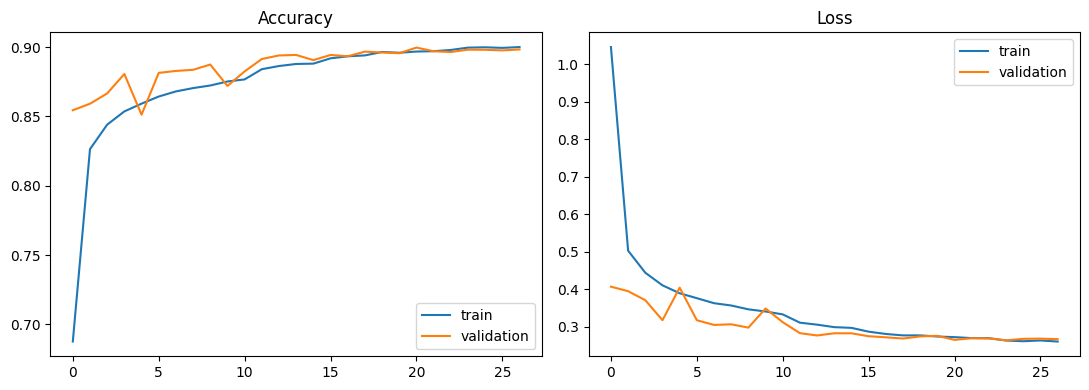

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, k in zip(ax, ["accuracy", "loss"]):
    a.plot(hist.history[k], label="train"); a.plot(hist.history["val_" + k], label="validation")
    a.set_title(k.capitalize()); a.legend()
plt.tight_layout(); plt.savefig(f"{OUT}/training_curves.png", dpi=150); plt.show()

## 9. Confusion matrix & mistakes
Most errors are genuinely ambiguous pairs such as O/0, I/1, l/1.

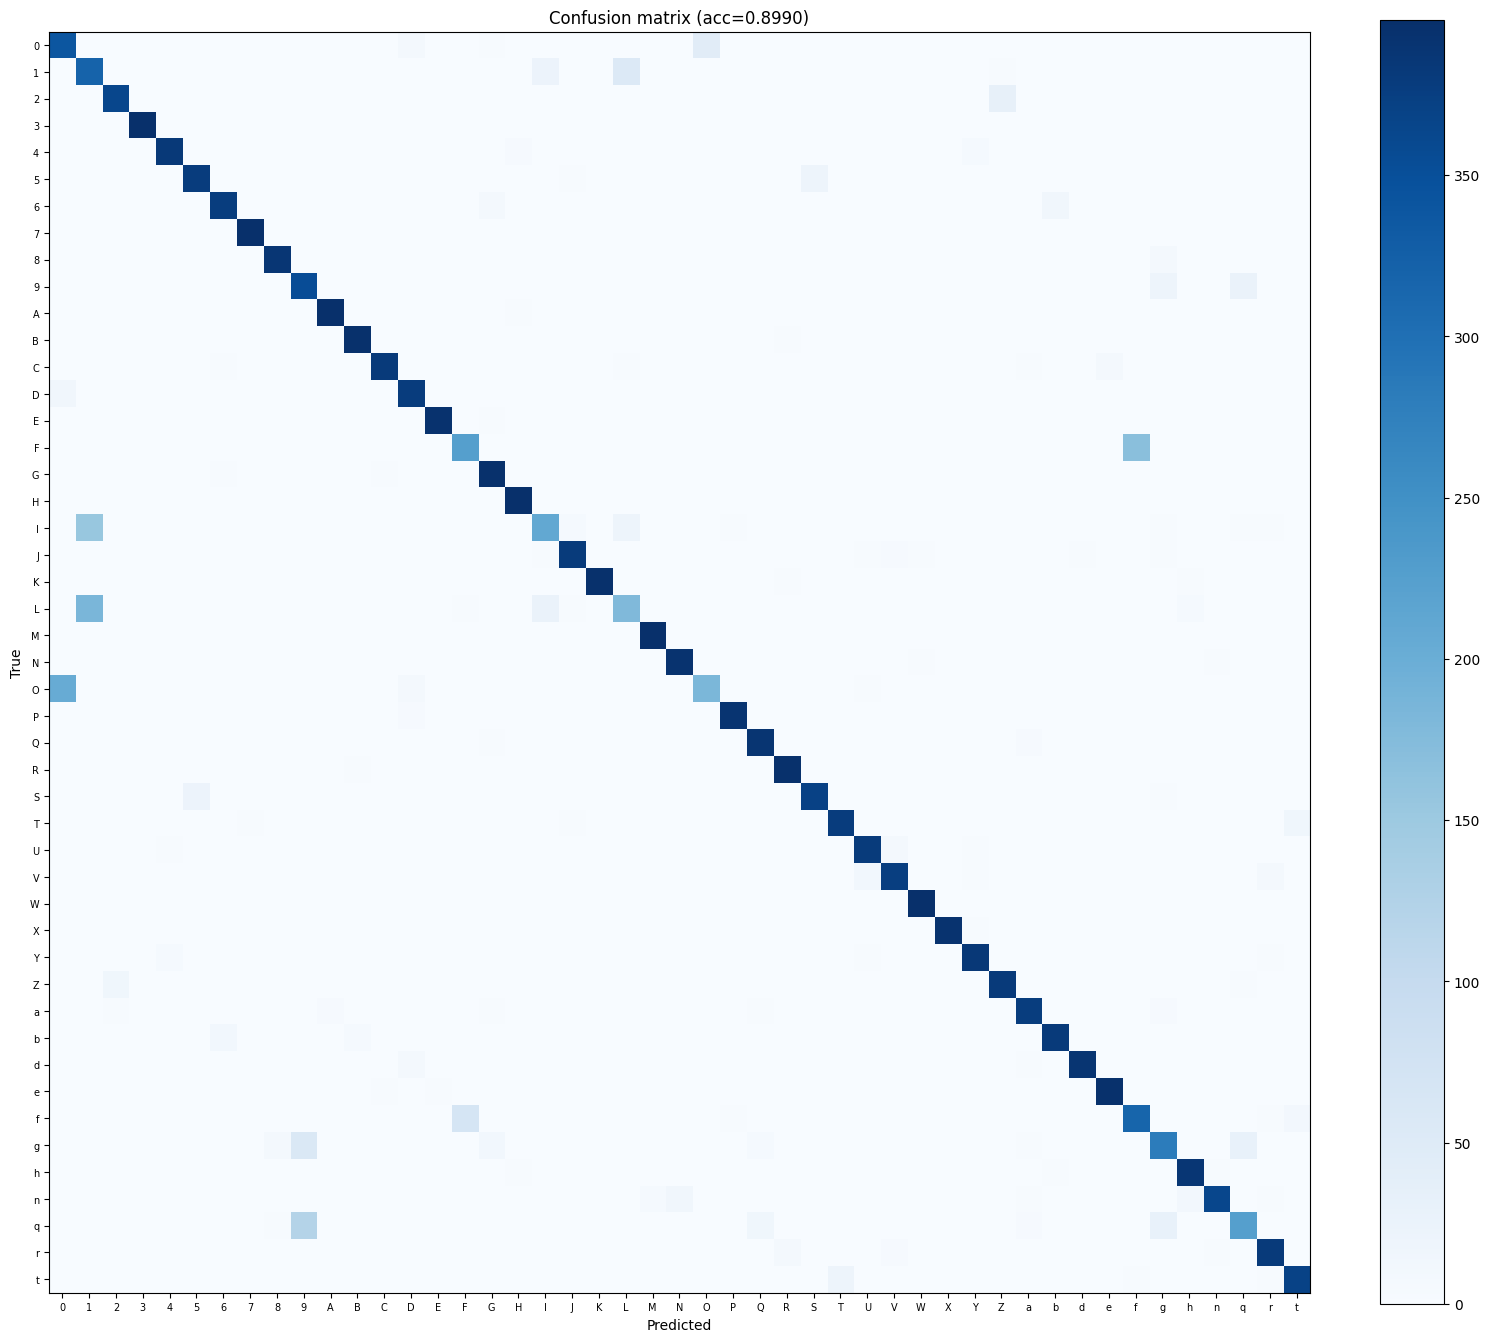

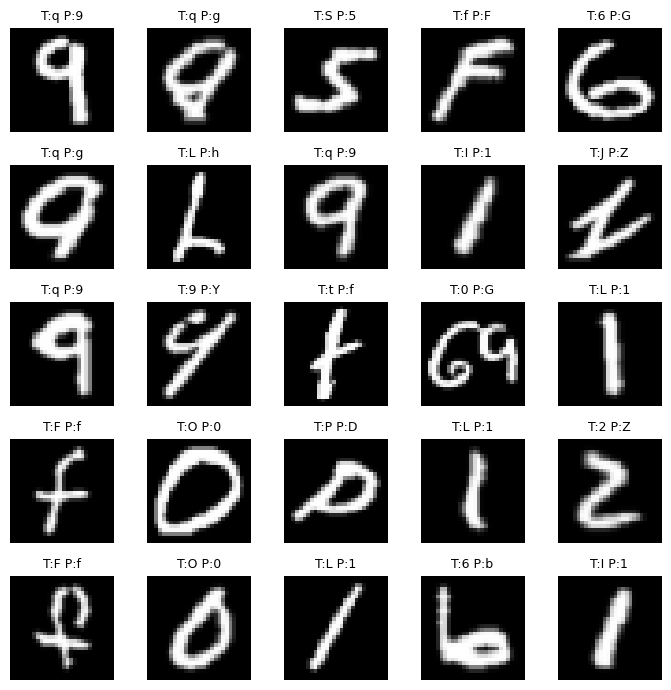

Most confused (true->pred): O->0(203), L->1(184), F->f(169), I->1(155), q->9(122), f->F(67), g->9(57), 1->L(53), 0->O(45), 2->Z(32)


In [9]:
cm = confusion_matrix(y_te, pred)
plt.figure(figsize=(max(6, N // 3),) * 2)
plt.imshow(cm, cmap="Blues"); plt.colorbar(fraction=0.046)
plt.xticks(range(N), list(charset), fontsize=7); plt.yticks(range(N), list(charset), fontsize=7)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title(f"Confusion matrix (acc={acc:.4f})")
plt.tight_layout(); plt.savefig(f"{OUT}/confusion_matrix.png", dpi=150); plt.show()

wrong = np.where(pred != y_te)[0][:25]
show_grid(x_te[wrong], [f"T:{charset[y_te[i]]} P:{charset[pred[i]]}" for i in wrong], f"{OUT}/mistakes.png")
np.fill_diagonal(cm, 0)
top = np.dstack(np.unravel_index(np.argsort(cm.ravel())[::-1][:10], cm.shape))[0]
print("Most confused (true->pred):", ", ".join(f"{charset[i]}->{charset[j]}({cm[i, j]})" for i, j in top))

## 10. Save & predict your own handwriting
Upload a photo of a character and call `predict_image(path)`.

In [10]:
cnn.save(f"{OUT}/cnn_{DATASET}.keras")
metrics = {"dataset": DATASET, "charset": charset, "cnn_test_accuracy": round(float(acc), 4)}


def predict_image(path):
    """Predict a character from your own photo/drawing (upload it as a Kaggle input)."""
    from PIL import Image, ImageOps
    a = np.asarray(ImageOps.grayscale(Image.open(path)), dtype=np.float32)
    if a.mean() > 127:
        a = 255 - a                                          # dark ink on white paper -> invert
    a[a < 50] = 0
    ys, xs = np.nonzero(a)
    a = a[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
    s = 20 / max(a.shape)
    small = Image.fromarray(a.astype(np.uint8)).resize((max(1, round(a.shape[1] * s)), max(1, round(a.shape[0] * s))))
    canvas = Image.new("L", (28, 28)); canvas.paste(small, ((28 - small.width) // 2, (28 - small.height) // 2))
    p = cnn.predict((np.asarray(canvas, np.float32) / 255.0)[None, ..., None], verbose=0)[0]
    return [(charset[i], round(float(p[i]), 3)) for i in p.argsort()[::-1][:3]]

# Part B — Word recognition with CRNN (extension)
The task says the model is *extendable to full words with sequence modelling (CRNN)*. Skip these cells if you only need Part A.

## 11. Synthetic handwritten words
Words of 1–8 letters are made by joining random EMNIST letter images. Train words use train letters, test words use test letters → evaluation on unseen handwriting.

In [17]:
H, W, MAX_LEN, BLANK = 28, 256, 8, 0                     # CTC blank = 0, letters = 1..26

def read_letters(part):
    f = glob.glob(f"{INPUT}/**/emnist-letters-{part}.csv", recursive=True)[0]
    d = pd.read_csv(f, header=None).values
    return d[:, 1:].reshape(-1, 28, 28).transpose(0, 2, 1).astype(np.uint8), d[:, 0].astype(int) - 1   # 1..26 -> 0..25

(lx_tr, ly_tr), (lx_te, ly_te) = read_letters("train"), read_letters("test")
# Kaggle letters TEST csv only has A-S -> hold out 15% of TRAIN images (never trained on) as extra test images
hold = np.random.default_rng(0).permutation(len(ly_tr))
cut = int(0.15 * len(hold))
lx_te, ly_te = np.concatenate([lx_te, lx_tr[hold[:cut]]]), np.concatenate([ly_te, ly_tr[hold[:cut]]])
lx_tr, ly_tr = lx_tr[hold[cut:]], ly_tr[hold[cut:]]
print(f"train {len(ly_tr)} images | test {len(ly_te)} images | {len(np.unique(ly_te))} letters in test")
LETTERS = CHARSETS["letters"]

class WordGen:
    """Synthesise word images by joining random letter images (train / test images kept apart)."""
    def __init__(self, imgs, labels, seed):
        self.rng = np.random.default_rng(seed)
        self.pool = [imgs[labels == c] for c in range(26)]
        self.classes = np.array([c for c in range(26) if len(self.pool[c]) > 0])
        assert len(self.classes) == 26, f"letters missing: {set(range(26)) - set(self.classes)}"

    def batch(self, n):
        L = self.rng.integers(1, MAX_LEN + 1, n)
        X = np.zeros((n, H, W, 1), np.float32)
        Y = np.zeros((n, MAX_LEN), np.int32)
        for i, l in enumerate(L):
            ids = self.rng.choice(self.classes, l)
            x = int(self.rng.integers(0, 6))
            for c in ids:
                ch = self.pool[c][self.rng.integers(len(self.pool[c]))].astype(np.float32) / 255.0
                cols = np.where(ch.max(0) > 0.1)[0]
                ch = np.roll(ch[:, cols.min():cols.max() + 1] if len(cols) else ch, int(self.rng.integers(-2, 3)), 0)
                if x + ch.shape[1] > W:
                    break
                X[i, :, x:x + ch.shape[1], 0] = np.maximum(X[i, :, x:x + ch.shape[1], 0], ch)
                x = max(0, x + ch.shape[1] + int(self.rng.integers(-2, 5)))
            Y[i, :l] = ids + 1
        return X, Y, L.astype(np.int32)

train_gen, test_gen = WordGen(lx_tr, ly_tr, 1), WordGen(lx_te, ly_te, 2)

train 75480 images | test 28120 images | 26 letters in test


## 12. CRNN model
CNN feature extractor → 64 image columns as a sequence → 2 × BiLSTM → per-column character scores.

In [19]:
inp = keras.Input((H, W, 1))
x = inp
for f, pool in [(32, (2, 2)), (64, (2, 2)), (128, (2, 1)), (128, None)]:
    x = layers.ReLU()(layers.BatchNormalization()(layers.Conv2D(f, 3, padding="same", use_bias=False)(x)))
    if pool:
        x = layers.MaxPooling2D(pool)(x)
x = layers.Reshape((W // 4, (H // 8) * 128))(layers.Permute((2, 1, 3))(x))   # 64 time steps (columns)
x = layers.Dropout(0.25)(layers.Dense(128, activation="relu")(x))
x = layers.Bidirectional(layers.LSTM(128, return_sequences=True, dropout=0.25))(x)
x = layers.Bidirectional(layers.LSTM(64, return_sequences=True, dropout=0.25))(x)
crnn = keras.Model(inp, layers.Dense(27)(x), name="crnn")                   # 26 letters + blank (logits)
opt = keras.optimizers.Adam(keras.optimizers.schedules.CosineDecay(1e-3, CRNN_STEPS, alpha=0.05))
T = W // 4

## 13. CTC loss, greedy decoding & metrics
CTC learns the alignment between image columns and characters, so no per-letter positions are needed. Metrics: character error rate (CER) and word accuracy.

In [21]:
@tf.function
def train_step(X, Y, L):
    with tf.GradientTape() as tape:
        logits = crnn(X, training=True)
        loss = tf.reduce_mean(tf.nn.ctc_loss(labels=Y, logits=logits, label_length=L,
                                             logit_length=tf.fill([tf.shape(X)[0]], T),
                                             logits_time_major=False, blank_index=BLANK))
    g, _ = tf.clip_by_global_norm(tape.gradient(loss, crnn.trainable_variables), 5.0)
    opt.apply_gradients(zip(g, crnn.trainable_variables))
    return loss

def decode(logits):                                      # greedy CTC: collapse repeats, drop blanks
    out = []
    for seq in logits.argmax(-1):
        w, prev = [], -1
        for t in seq:
            if t != prev and t != BLANK:
                w.append(int(t) - 1)
            prev = t
        out.append(w)
    return out

def edit_distance(a, b):
    d = list(range(len(b) + 1))
    for i in range(1, len(a) + 1):
        prev, d[0] = d[0], i
        for j in range(1, len(b) + 1):
            cur = d[j]; d[j] = min(d[j] + 1, d[j - 1] + 1, prev + (a[i - 1] != b[j - 1])); prev = cur
    return d[-1]

def evaluate_words(n=2000, bs=200):
    err = chars = ok = 0
    for _ in range(n // bs):
        X, Y, L = test_gen.batch(bs)
        for p, y, l in zip(decode(crnn(X, training=False).numpy()), Y, L):
            t = [int(c) - 1 for c in y[:l]]
            err += edit_distance(p, t); chars += l; ok += p == t
    return err / chars, ok / n

## 14. Train the CRNN

In [22]:
losses = []
for step in range(1, CRNN_STEPS + 1):
    losses.append(float(train_step(*train_gen.batch(64))))
    if step % 500 == 0:
        cer, wacc = evaluate_words(1000)
        print(f"step {step:5d}  ctc_loss {np.mean(losses[-500:]):.3f}  test CER {cer:.2%}  word acc {wacc:.2%}")
cer, wacc = evaluate_words(4000)
print(f"\nCRNN FINAL on 4000 unseen words: CER = {cer:.3%}, word accuracy = {wacc:.2%}")

step   500  ctc_loss 9.873  test CER 63.37%  word acc 8.80%
step  1000  ctc_loss 1.841  test CER 11.17%  word acc 60.30%
step  1500  ctc_loss 1.360  test CER 8.07%  word acc 69.30%
step  2000  ctc_loss 1.152  test CER 8.25%  word acc 69.50%
step  2500  ctc_loss 1.019  test CER 6.61%  word acc 74.60%
step  3000  ctc_loss 0.932  test CER 6.29%  word acc 76.00%
step  3500  ctc_loss 0.855  test CER 6.78%  word acc 74.70%
step  4000  ctc_loss 0.799  test CER 5.76%  word acc 76.50%
step  4500  ctc_loss 0.736  test CER 5.54%  word acc 78.00%
step  5000  ctc_loss 0.705  test CER 5.91%  word acc 76.90%
step  5500  ctc_loss 0.662  test CER 6.26%  word acc 76.00%
step  6000  ctc_loss 0.659  test CER 5.67%  word acc 77.00%

CRNN FINAL on 4000 unseen words: CER = 5.549%, word accuracy = 78.42%


## 15. Predictions on unseen words

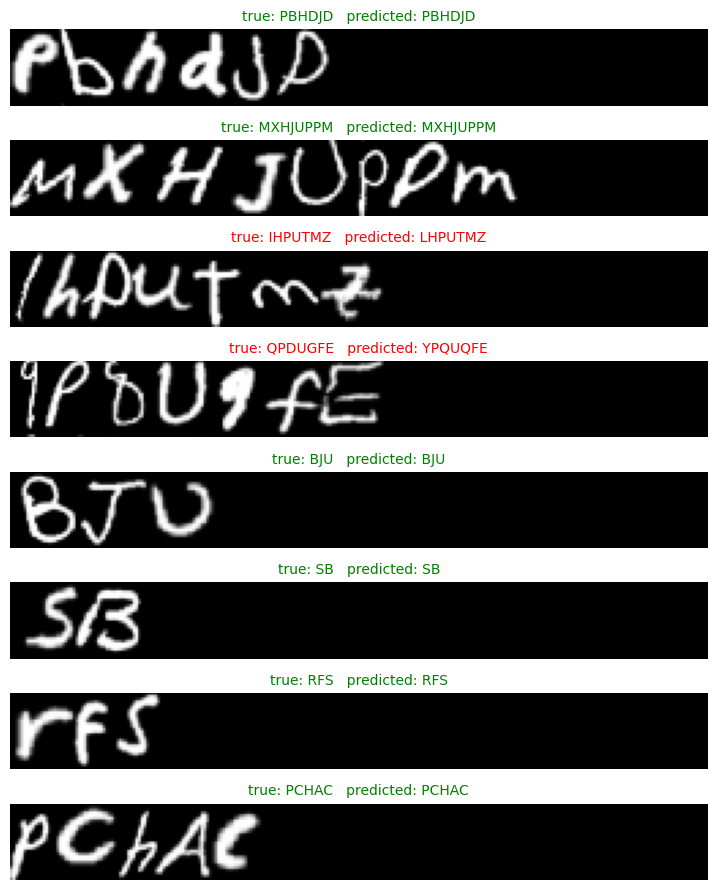

In [23]:
X, Y, L = test_gen.batch(8)
P = decode(crnn(X, training=False).numpy())
plt.figure(figsize=(10, 9))
for i in range(8):
    t, g = "".join(LETTERS[c - 1] for c in Y[i, :L[i]]), "".join(LETTERS[c] for c in P[i])
    plt.subplot(8, 1, i + 1); plt.imshow(X[i, ..., 0], cmap="gray"); plt.axis("off")
    plt.title(f"true: {t}   predicted: {g}", fontsize=10, color="green" if t == g else "red")
plt.tight_layout(); plt.savefig(f"{OUT}/crnn_word_predictions.png", dpi=120); plt.show()
crnn.save(f"{OUT}/crnn_words.keras")
metrics.update({"crnn_cer": round(cer, 4), "crnn_word_accuracy": round(wacc, 4)})

## 16. Save metrics

In [24]:
json.dump(metrics, open(f"{OUT}/metrics.json", "w"), indent=2)
print("\nMetrics:", metrics, f"\nSaved to {OUT}/   (use predict_image('/kaggle/input/.../my_letter.png'))")


Metrics: {'dataset': 'balanced', 'charset': '0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZabdefghnqrt', 'cnn_test_accuracy': 0.899, 'crnn_cer': np.float64(0.0555), 'crnn_word_accuracy': 0.7843} 
Saved to /kaggle/working/outputs/   (use predict_image('/kaggle/input/.../my_letter.png'))
